In [ ]:
# PerformIQ AI: Module 3, Early Warning and Trend Detection

# **What this notebook does:** It identifies students who are likely to **fail or withdraw** by looking at how they behave during the course: how active they are on the learning platform and how they do in assessments. It also checks **how early** the system can spot them.

# **Dataset:** OULAD (Open University Learning Analytics Dataset), real data with about 32,600 course enrolments and over 10 million click records.

# **Why this is a separate notebook:**
# 1. **Different dataset.** Notebook 1 uses a one-row-per-student habit dataset. OULAD is a set of seven linked tables (students, assessments, daily clicks, etc.) and tracks students over time.
# 2. **Different problem.** Notebook 1 predicts a score (regression). Here we predict a category, at risk or not (classification), at different points in time.
# 3. **Different preparation.** Features must be built from raw records using only data available up to a chosen day, which needs its own code.
# 4. **Size.** The click table has over 10 million rows and is memory-heavy, so it is kept apart from the lighter notebook.

# Notebook 1 answers "what score will this student get?". This notebook answers "who is slipping during the course, and how early can we tell?"

In [1]:
### 1. Imports and File Check
# We import the libraries and confirm that all seven OULAD files are present in the project folder.
    
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = "."   # files are in the same folder as the notebook

needed = ["courses.csv", "assessments.csv", "studentInfo.csv", "studentRegistration.csv",
          "studentAssessment.csv", "studentVle.csv", "vle.csv"]

for f in needed:
    print(f"{f:25s}", "FOUND" if os.path.exists(f"{DATA_DIR}/{f}") else "MISSING")

courses.csv               FOUND
assessments.csv           FOUND
studentInfo.csv           FOUND
studentRegistration.csv   FOUND
studentAssessment.csv     FOUND
studentVle.csv            FOUND
vle.csv                   FOUND


In [2]:
import warnings
warnings.filterwarnings("ignore", message="Skipping features without any observed values")

In [3]:
### 2. Loading the Small Tables
# Six small tables are loaded:
# courses, assessments (what is due and when), student info (age, education, final result), registration dates, 
# student assessment scores and the course materials list.
# The printed shapes confirm they loaded fully.
    
courses       = pd.read_csv(f"{DATA_DIR}/courses.csv")
assessments   = pd.read_csv(f"{DATA_DIR}/assessments.csv")
student_info  = pd.read_csv(f"{DATA_DIR}/studentInfo.csv")
student_reg   = pd.read_csv(f"{DATA_DIR}/studentRegistration.csv")
student_assess = pd.read_csv(f"{DATA_DIR}/studentAssessment.csv")
vle           = pd.read_csv(f"{DATA_DIR}/vle.csv")

for name, t in [("courses", courses), ("assessments", assessments), ("studentInfo", student_info),
                ("studentRegistration", student_reg), ("studentAssessment", student_assess), ("vle", vle)]:
    print(f"{name:22s} {t.shape}")

courses                (22, 3)
assessments            (206, 6)
studentInfo            (32593, 12)
studentRegistration    (32593, 5)
studentAssessment      (173912, 5)
vle                    (6364, 6)


In [4]:
### 3. Loading the Click Data
# `studentVle` records every time a student used the online learning platform (about 10.6 million rows). 
# It is loaded with small data types to save memory. 
# This is the most important behavioural data, because a student who stops logging in is often an early sign of trouble.
    
student_vle = pd.read_csv(
    f"{DATA_DIR}/studentVle.csv",
    dtype={"id_site": "int32", "id_student": "int32", "date": "int16", "sum_click": "int16"},
    usecols=["code_module", "code_presentation", "id_student", "id_site", "date", "sum_click"],
)
print("studentVle shape:", student_vle.shape)
print("Memory (MB):", round(student_vle.memory_usage(deep=True).sum() / 1e6))
student_vle.head()

studentVle shape: (10655280, 6)
Memory (MB): 1257


,code_module,code_presentation,id_student,id_site,date,sum_click
0,AAA,2013J,28400,546652,-10,4
1,AAA,2013J,28400,546652,-10,1
2,AAA,2013J,28400,546652,-10,1
3,AAA,2013J,28400,546614,-10,11
4,AAA,2013J,28400,546714,-10,1


In [5]:
### 4. Understanding the Outcomes
# About 38% of enrolments Pass, 9% get Distinction, 22% Fail and 31% Withdraw. 
# We treat **Fail and Withdrawn as "at risk"**, which is roughly half of all enrolments. 
# A student can take several courses, so there are 28,785 unique students across 32,593 enrolments. 
# That is why we later split data by student, not by row.
    
KEYS = ["code_module", "code_presentation", "id_student"]

print("Final result counts:")
display(student_info["final_result"].value_counts())
print("\nShare:")
display(student_info["final_result"].value_counts(normalize=True).round(3))

print("\nStudents per module-presentation:")
display(student_info.groupby(["code_module", "code_presentation"]).size().unstack())

print("\nUnique students:", student_info["id_student"].nunique(), "| enrolments:", len(student_info))

print("\nMissing values in studentInfo:")
display(student_info.isnull().sum()[lambda s: s > 0])

print("\nAssessment types:")
display(assessments["assessment_type"].value_counts())

Final result counts:


final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64


Share:


final_result
Pass           0.379
Withdrawn      0.312
Fail           0.216
Distinction    0.093
Name: proportion, dtype: float64


Students per module-presentation:


code_presentation,2013B,2013J,2014B,2014J
code_module,,,,
AAA,NaN,383.0,NaN,365.0
BBB,1767.0,2237.0,1613.0,2292.0
CCC,NaN,NaN,1936.0,2498.0
DDD,1303.0,1938.0,1228.0,1803.0
EEE,NaN,1052.0,694.0,1188.0
FFF,1614.0,2283.0,1500.0,2365.0
GGG,NaN,952.0,833.0,749.0



Unique students: 28785 | enrolments: 32593

Missing values in studentInfo:


imd_band    1111
dtype: int64


Assessment types:


assessment_type
TMA     106
CMA      76
Exam     24
Name: count, dtype: int64

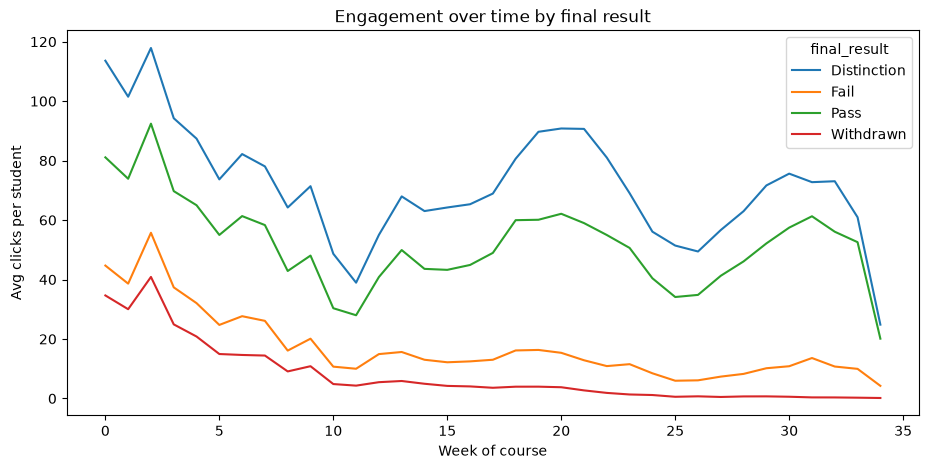

In [6]:
### 5. Engagement Over Time
# This chart shows the average weekly platform activity for each final result. Distinction and Pass students are consistently more active.
# Fail and Withdrawn students are much less active, and Withdrawn activity falls towards zero. Part of that fall is because they leave the course.
# The main point is that different outcomes show different engagement patterns from early on, which is what makes early warning possible.
    
vle_week = student_vle[(student_vle["date"] >= 0) & (student_vle["date"] <= 240)].copy()
vle_week["week"] = vle_week["date"] // 7

weekly = vle_week.groupby(KEYS + ["week"], as_index=False)["sum_click"].sum()
weekly = weekly.merge(student_info[KEYS + ["final_result"]], on=KEYS, how="left")

n_by_outcome = student_info["final_result"].value_counts()
curve = weekly.groupby(["final_result", "week"])["sum_click"].sum().unstack(0)
curve = curve / n_by_outcome            # average clicks per student per week

curve.plot(figsize=(11, 5))
plt.xlabel("Week of course")
plt.ylabel("Avg clicks per student")
plt.title("Engagement over time by final result")
plt.show()

del vle_week, weekly                    # free memory

In [7]:
### 6. Building Features Using Only Past Data
# This function creates the model's inputs **using only data up to a chosen cutoff day**. Nothing after that day is used, so it behaves like a real early-warning system. Students who have already withdrawn before the cutoff are removed, since their outcome is already known.

# Features include:
# - **Activity:** total clicks, number of active days, clicks in the last 14 days and the 14 days before, and the change between them (negative means engagement is dropping)
# - **Assessments:** how many were due, submitted and missed, the average score, the score trend (last score minus first score) and how late work was submitted
# - **Background:** previous attempts, studied credits, education level, age band and similar

# The target is `at_risk` (1 = Fail or Withdrawn, 0 = Pass or Distinction).

def build_features(cutoff):
    # 1) Base table: students still registered at the cutoff day
    base = student_info.merge(
        student_reg[KEYS + ["date_registration", "date_unregistration"]], on=KEYS, how="left")
    base = base[~(base["date_unregistration"] <= cutoff)].copy()   # already withdrawn = not a prediction
    base["at_risk"] = base["final_result"].isin(["Fail", "Withdrawn"]).astype(int)

    # 2) VLE click features (daily clicks up to cutoff)
    v = student_vle[student_vle["date"] <= cutoff]
    daily = v.groupby(KEYS + ["date"], as_index=False)["sum_click"].sum()

    total = daily.groupby(KEYS)["sum_click"].agg(total_clicks="sum", active_days="size")
    last14 = (daily[daily["date"] > cutoff - 14]
              .groupby(KEYS)["sum_click"].sum().rename("clicks_last14"))
    prev14 = (daily[(daily["date"] > cutoff - 28) & (daily["date"] <= cutoff - 14)]
              .groupby(KEYS)["sum_click"].sum().rename("clicks_prev14"))
    clicks = pd.concat([total, last14, prev14], axis=1).reset_index()

    # 3) Assessment features (non-exam assessments already due by the cutoff)
    a = assessments[(assessments["assessment_type"] != "Exam") & (assessments["date"] <= cutoff)]
    a = a[["code_module", "code_presentation", "id_assessment", "date"]].rename(columns={"date": "due_date"})

    sa = student_assess[["id_assessment", "id_student", "date_submitted", "score"]]
    sa = sa[sa["date_submitted"] <= cutoff]

    due = base[KEYS].merge(a, on=["code_module", "code_presentation"], how="inner")
    due = due.merge(sa, on=["id_assessment", "id_student"], how="left")
    due["submitted"] = due["date_submitted"].notna()
    due["days_late"] = due["date_submitted"] - due["due_date"]
    due = due.sort_values("due_date")

    ass = due.groupby(KEYS).agg(
        n_due=("id_assessment", "size"),
        n_submitted=("submitted", "sum"),
        avg_score=("score", "mean"),
        first_score=("score", "first"),
        last_score=("score", "last"),
        avg_days_late=("days_late", "mean"),
    ).reset_index()

    # 4) Combine everything
    df_c = base.merge(clicks, on=KEYS, how="left").merge(ass, on=KEYS, how="left")

    for c in ["total_clicks", "active_days", "clicks_last14", "clicks_prev14", "n_due", "n_submitted"]:
        df_c[c] = df_c[c].fillna(0)                      # no record = no activity

    df_c["click_change"] = df_c["clicks_last14"] - df_c["clicks_prev14"]
    df_c["n_missed"] = df_c["n_due"] - df_c["n_submitted"]
    df_c["submit_rate"] = np.where(df_c["n_due"] > 0, df_c["n_submitted"] / df_c["n_due"], np.nan)
    df_c["score_trend"] = df_c["last_score"] - df_c["first_score"]   # negative = declining
    return df_c

CAT_COLS = ["code_module", "gender", "region", "highest_education", "imd_band", "age_band", "disability"]
NUM_COLS = ["num_of_prev_attempts", "studied_credits", "date_registration",
            "total_clicks", "active_days", "clicks_last14", "clicks_prev14", "click_change",
            "n_due", "n_submitted", "n_missed", "submit_rate",
            "avg_score", "first_score", "last_score", "score_trend", "avg_days_late"]
FEATURES = CAT_COLS + NUM_COLS
print("Function ready. Features:", len(FEATURES))

Function ready. Features: 24


In [8]:
### 7. Features at Day 60
# We build the feature table as if we were standing on day 60 of the course.
# Some score columns are missing for students who have not submitted anything yet. 
# That is expected, and the pipeline handles it, treating "no submission yet" as a signal in itself.
    
CUTOFF = 60
data = build_features(CUTOFF)

print("Shape:", data.shape)
print("At-risk share (Fail or Withdrawn after day 60):", round(data["at_risk"].mean(), 3))
print("\nMissing values in features:")
display(data[FEATURES].isnull().sum()[lambda s: s > 0])
data[KEYS + ["at_risk"] + NUM_COLS].head()

Shape: (26361, 29)
At-risk share (Fail or Withdrawn after day 60): 0.416

Missing values in features:


imd_band              998
date_registration       7
submit_rate          2403
avg_score            3982
first_score          3982
last_score           3982
score_trend          3982
avg_days_late        3975
dtype: int64

,code_module,code_presentation,id_student,at_risk,num_of_prev_attempts,studied_credits,date_registration,total_clicks,active_days,clicks_last14,...,click_change,n_due,n_submitted,n_missed,submit_rate,avg_score,first_score,last_score,score_trend,avg_days_late
0,AAA,2013J,11391,0,0,240,-159.0,529.0,18.0,42.0,...,-18.0,2.0,2.0,0.0,1.0,81.5,78.0,85.0,7.0,-1.0
1,AAA,2013J,28400,0,0,60,-53.0,669.0,26.0,44.0,...,39.0,2.0,2.0,0.0,1.0,69.0,70.0,68.0,-2.0,0.5
2,AAA,2013J,31604,0,0,60,-52.0,816.0,41.0,83.0,...,-95.0,2.0,2.0,0.0,1.0,71.5,72.0,71.0,-1.0,-2.5
3,AAA,2013J,32885,0,0,60,-176.0,605.0,28.0,4.0,...,-12.0,2.0,1.0,1.0,0.5,69.0,69.0,69.0,0.0,7.0
4,AAA,2013J,38053,0,0,60,-110.0,1005.0,49.0,129.0,...,-13.0,2.0,1.0,1.0,0.5,79.0,79.0,79.0,0.0,0.0


In [9]:
### 8. Train/Test Split by Student
# We split so that all enrolments of the same student are in either the training set or the test set, never both.
# Otherwise the model could recognise a student's habits from training and look better than it really is. 
# 80% of students go to training and 20% to testing.
    
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score

def make_preprocessor():
    num_tf = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                       ("sc", StandardScaler())])
    cat_tf = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                       ("oh", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", num_tf, NUM_COLS), ("cat", cat_tf, CAT_COLS)])

def split_by_student(frame, seed=42):
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
    tr, te = next(gss.split(frame, groups=frame["id_student"]))
    return frame.iloc[tr], frame.iloc[te]

train_df, test_df = split_by_student(data)
X_train, y_train = train_df[FEATURES], train_df["at_risk"]
X_test,  y_test  = test_df[FEATURES],  test_df["at_risk"]
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("At-risk share  train:", round(y_train.mean(), 3), " test:", round(y_test.mean(), 3))

Train: (21067, 24) | Test: (5294, 24)
At-risk share  train: 0.415  test: 0.421


In [10]:
### 9. Training and Comparing Models
# This is a **classification** problem, so we use different metrics from Notebook 1:
# - **ROC-AUC:** how well the model separates at-risk from safe students (0.5 = guessing, 1.0 = perfect)
# - **Recall:** of the students who really were at risk, how many we caught
# - **Precision:** of the students we flagged, how many really were at risk
# - **F1:** a balance of precision and recall

# HistGradientBoosting performs best (ROC-AUC about 0.84, precision about 0.78, recall about 0.63). The Dummy model scores 0.5 as expected.

models = {
    "Dummy": DummyClassifier(strategy="prior"),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=10, n_jobs=-1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, random_state=42),
}

trained, rows = {}, []
for name, model in models.items():
    print("Training", name, "...")
    pipe = Pipeline([("prep", make_preprocessor()), ("model", model)])
    pipe.fit(X_train, y_train)
    prob = pipe.predict_proba(X_test)[:, 1]
    pred = (prob >= 0.5).astype(int)
    trained[name] = pipe
    rows.append({"Model": name,
                 "ROC_AUC": roc_auc_score(y_test, prob),
                 "Precision": precision_score(y_test, pred, zero_division=0),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred)})

results = pd.DataFrame(rows).sort_values("ROC_AUC", ascending=False).reset_index(drop=True)
print("\nModel comparison (at-risk = Fail or Withdrawn):")
display(results.round(3))

Training Dummy ...
Training Logistic Regression ...
Training Random Forest ...
Training HistGradientBoosting ...

Model comparison (at-risk = Fail or Withdrawn):


,Model,ROC_AUC,Precision,Recall,F1
0,HistGradientBoosting,0.837,0.782,0.628,0.697
1,Random Forest,0.834,0.786,0.608,0.686
2,Logistic Regression,0.822,0.780,0.593,0.674
3,Dummy,0.500,0.000,0.000,0.000


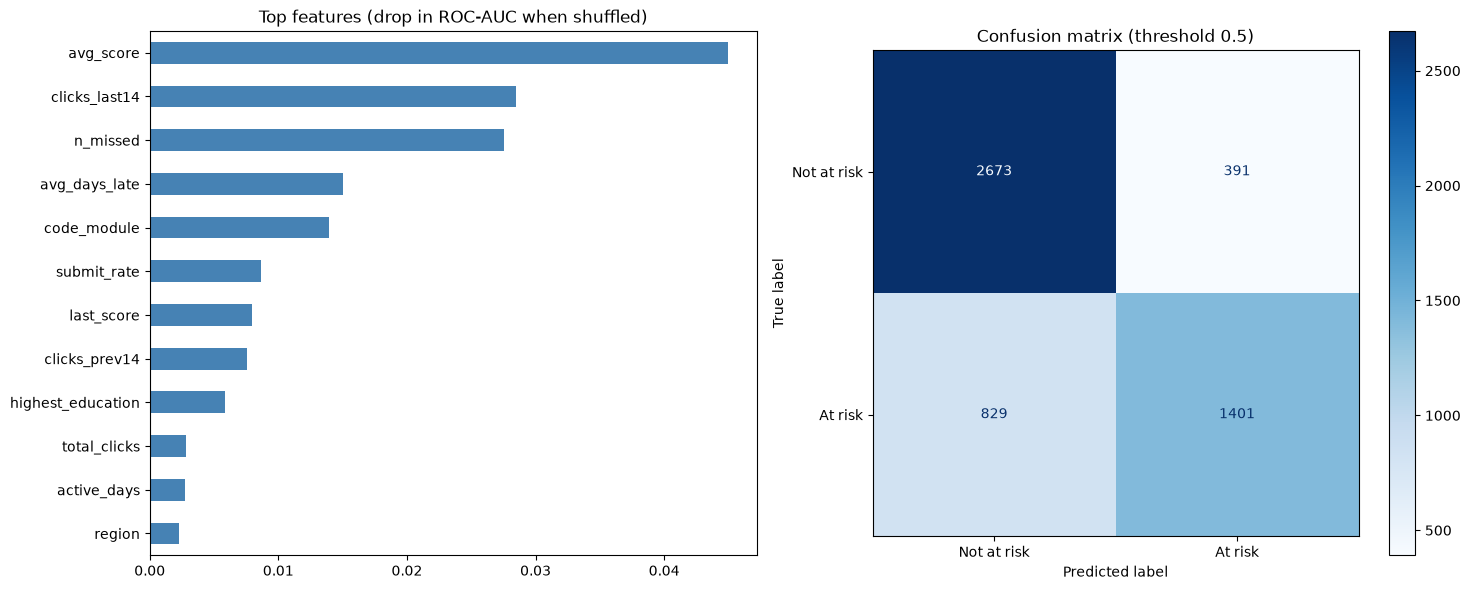

In [11]:
### 10. What Signals Matter and Where the Model Makes Mistakes
# The importance chart shows that average score, recent activity (last 14 days) and the number of missed assessments matter most. 
# Recent activity matters more than total activity, which supports looking at what students are doing now.
# The confusion matrix shows the counts of correct and wrong predictions: students correctly flagged, students missed and students flagged by mistake.

from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay

best = trained["HistGradientBoosting"]

sample_idx = X_test.sample(min(5000, len(X_test)), random_state=42).index
perm = permutation_importance(best, X_test.loc[sample_idx], y_test.loc[sample_idx],
                              n_repeats=5, random_state=42, n_jobs=-1, scoring="roc_auc")
imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
imp.tail(12).plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Top features (drop in ROC-AUC when shuffled)")

ConfusionMatrixDisplay.from_estimator(best, X_test, y_test, ax=axes[1],
                                      display_labels=["Not at risk", "At risk"], cmap="Blues")
axes[1].set_title("Confusion matrix (threshold 0.5)")
plt.tight_layout()
plt.show()

done day 0
done day 20
done day 40
done day 60
done day 90
done day 120
done day 180


,cutoff_day,students,at_risk_share,ROC_AUC,Recall,Precision
0,0,29496,0.478,0.712,0.599,0.658
1,20,27913,0.449,0.758,0.568,0.694
2,40,27061,0.431,0.809,0.599,0.759
3,60,26361,0.416,0.837,0.628,0.782
4,90,25562,0.398,0.868,0.657,0.806
5,120,24777,0.379,0.898,0.670,0.845
6,180,23275,0.339,0.935,0.745,0.890


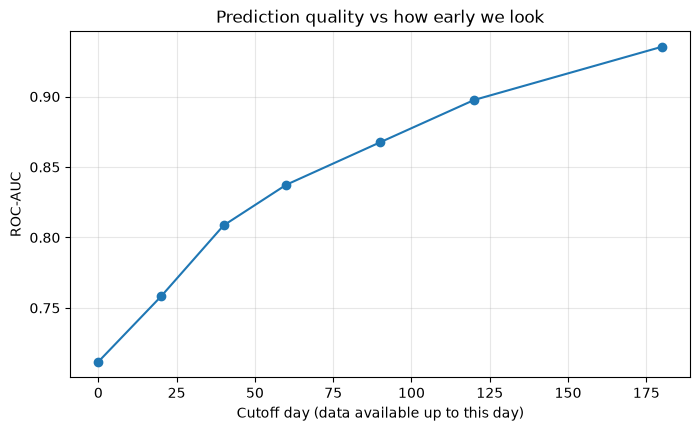

In [12]:
### 11. How Early Can We Detect At-Risk Students?
# We repeat the whole process at different cutoff days (0, 20, 40, 60, 90, 120, 180). 
# The more of the course we have seen, the better the prediction. 
# ROC-AUC rises from about 0.71 at day 0 (only background information) to about 0.81 by day 40 and 0.94 by day 180. 
# So useful warnings are possible early in the course, and they become more reliable over time.

# **Note:** At later cutoffs more students have already withdrawn and are removed, 
# so the groups differ slightly between rows and the comparison is not perfectly like-for-like.
# This step is slow because the features are rebuilt seven times.

rows = []
for day in [0, 20, 40, 60, 90, 120, 180]:
    d = build_features(day)
    tr, te = split_by_student(d)
    pipe = Pipeline([("prep", make_preprocessor()),
                     ("model", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, random_state=42))])
    pipe.fit(tr[FEATURES], tr["at_risk"])
    prob = pipe.predict_proba(te[FEATURES])[:, 1]
    pred = (prob >= 0.5).astype(int)
    rows.append({"cutoff_day": day, "students": len(d), "at_risk_share": d["at_risk"].mean(),
                 "ROC_AUC": roc_auc_score(te["at_risk"], prob),
                 "Recall": recall_score(te["at_risk"], pred),
                 "Precision": precision_score(te["at_risk"], pred)})
    print("done day", day)

early = pd.DataFrame(rows)
display(early.round(3))

plt.figure(figsize=(8, 4.5))
plt.plot(early["cutoff_day"], early["ROC_AUC"], marker="o")
plt.xlabel("Cutoff day (data available up to this day)")
plt.ylabel("ROC-AUC")
plt.title("Prediction quality vs how early we look")
plt.grid(alpha=0.3)
plt.show()

In [13]:
### 12. Risk Levels and Decline Flags
# Each student's predicted probability of being at risk is converted into High (70% or more), Medium (40% to 70%) or Low risk. 
# The check against reality shows the groups are clearly separated: about 90% of High Risk students really were at risk, 
# compared with about 52% for Medium and 21% for Low. Low risk does not mean safe, because some students withdraw later in the course.

# We also test two simple decline flags: engagement dropped by half in the last two weeks, and scores fell by more than 10 points. 
# Both flagged groups have only slightly higher at-risk rates than unflagged students. 
# This means the level of activity and scores matters more than the change in them in this dataset.

test_df = test_df.copy()
test_df["risk_prob"] = best.predict_proba(X_test)[:, 1]

def risk_level(p):
    if p >= 0.70:
        return "High Risk"
    elif p >= 0.40:
        return "Medium Risk"
    return "Low Risk"

test_df["risk_level"] = test_df["risk_prob"].apply(risk_level)

# Trend / decline flags (rule-based, from the last 2 vs previous 2 weeks and the scores)
test_df["engagement_drop"] = (test_df["clicks_prev14"] > 0) & (test_df["clicks_last14"] < 0.5 * test_df["clicks_prev14"])
test_df["score_decline"] = test_df["score_trend"] < -10

print("Does the risk level match reality?")
display(test_df.groupby("risk_level")
        .agg(students=("at_risk", "size"), actual_at_risk_rate=("at_risk", "mean"))
        .reindex(["High Risk", "Medium Risk", "Low Risk"]).round(3))

print("\nDo the decline flags carry signal?")
for flag in ["engagement_drop", "score_decline"]:
    display(test_df.groupby(flag).agg(students=("at_risk", "size"),
                                      actual_at_risk_rate=("at_risk", "mean")).round(3))

Does the risk level match reality?


,students,actual_at_risk_rate
risk_level,,
High Risk,1141,0.898
Medium Risk,1103,0.519
Low Risk,3050,0.207



Do the decline flags carry signal?


,students,actual_at_risk_rate
engagement_drop,,
False,3730,0.410
True,1564,0.448


,students,actual_at_risk_rate
score_decline,,
False,4598,0.415
True,696,0.463


In [14]:
### 13. Recommendations and Teacher Dashboard
# Flagged students get rule-based suggestions based on their own data: a personal check-in if engagement has dropped,
# mentoring if scores are declining, deadline reminders if assessments were missed, remedial help for low scores, and extra support for repeat attempts. 
# The dashboard table lists the highest-risk students first. The cut-offs are our own choices and teachers should review them.

low_clicks_t = data["total_clicks"].quantile(0.25)

def recommend(r, max_items=4):
    recs = []
    if r["engagement_drop"]:
        recs.append("Engagement dropped sharply in last 2 weeks -> personal check-in message")
    if r["score_decline"]:
        recs.append("Scores are declining -> one-to-one mentoring and feedback")
    if r["n_missed"] >= 2:
        recs.append("Missed 2+ assessments -> deadline reminders, contact tutor")
    if pd.notna(r["avg_score"]) and r["avg_score"] < 55:
        recs.append("Low average score -> remedial practice / subject guidance")
    if r["total_clicks"] <= low_clicks_t:
        recs.append("Very low platform activity -> encourage use of course materials")
    if r["num_of_prev_attempts"] >= 1:
        recs.append("Repeat attempt -> extra support and study planning")
    return recs[:max_items] if recs else ["No specific concern found - continue monitoring"]

flagged = test_df[test_df["risk_level"] != "Low Risk"].copy()
flagged["recommendations"] = flagged.apply(recommend, axis=1)

dashboard = (flagged.sort_values(["risk_prob", "n_missed"], ascending=False)
             [["id_student", "code_module", "risk_prob", "risk_level", "total_clicks",
               "click_change", "n_missed", "avg_score", "score_trend", "recommendations"]]
             .reset_index(drop=True))
dashboard["risk_prob"] = dashboard["risk_prob"].round(2)

print(len(flagged), "students flagged out of", len(test_df))
display(dashboard.head(10))

top = dashboard.iloc[0]
print("\n--- Sample student report ---")
print("Student:", top["id_student"], "| Module:", top["code_module"])
print("Risk:", top["risk_prob"], f"({top['risk_level']})")
for r in top["recommendations"]:
    print("  -", r)

2244 students flagged out of 5294


,id_student,code_module,risk_prob,risk_level,total_clicks,click_change,n_missed,avg_score,score_trend,recommendations
0,425136,DDD,0.99,High Risk,111.0,0.0,3.0,8.0,0.0,"[Missed 2+ assessments -> deadline reminders, ..."
1,549498,DDD,0.99,High Risk,22.0,0.0,4.0,NaN,NaN,"[Missed 2+ assessments -> deadline reminders, ..."
2,588713,BBB,0.99,High Risk,9.0,0.0,3.0,NaN,NaN,"[Missed 2+ assessments -> deadline reminders, ..."
3,488364,BBB,0.99,High Risk,741.0,0.0,3.0,NaN,NaN,"[Missed 2+ assessments -> deadline reminders, ..."
4,55242,DDD,0.99,High Risk,8.0,-2.0,4.0,NaN,NaN,[Engagement dropped sharply in last 2 weeks ->...
5,321142,BBB,0.99,High Risk,0.0,0.0,3.0,NaN,NaN,"[Missed 2+ assessments -> deadline reminders, ..."
6,542472,BBB,0.99,High Risk,7.0,0.0,3.0,NaN,NaN,"[Missed 2+ assessments -> deadline reminders, ..."
7,205231,BBB,0.99,High Risk,0.0,0.0,3.0,NaN,NaN,"[Missed 2+ assessments -> deadline reminders, ..."
8,612506,FFF,0.99,High Risk,0.0,0.0,2.0,NaN,NaN,"[Missed 2+ assessments -> deadline reminders, ..."
9,538211,DDD,0.99,High Risk,140.0,0.0,4.0,NaN,NaN,"[Missed 2+ assessments -> deadline reminders, ..."



--- Sample student report ---
Student: 425136 | Module: DDD
Risk: 0.99 (High Risk)
  - Missed 2+ assessments -> deadline reminders, contact tutor
  - Low average score -> remedial practice / subject guidance
  - Very low platform activity -> encourage use of course materials


In [15]:
### 14. Saving the Model and Results
# The trained model (`performiq_oulad_model.joblib`) and the flagged-student list (`performiq_oulad_at_risk.csv`)
# are saved so the dashboard and backend can use them.

import joblib
joblib.dump(best, "performiq_oulad_model.joblib")
dashboard.to_csv("performiq_oulad_at_risk.csv", index=False)
print("Saved: performiq_oulad_model.joblib, performiq_oulad_at_risk.csv")

Saved: performiq_oulad_model.joblib, performiq_oulad_at_risk.csv


In [ ]:
# ## Summary of Results
# - **Best model:** HistGradientBoosting, ROC-AUC about 0.84 at day 60
# - **How early:** ROC-AUC about 0.81 by day 40 and 0.94 by day 180
# - **Risk levels work:** real at-risk rate was about 90% (High), 52% (Medium), 21% (Low)
# - **Main signals:** average score, recent platform activity, missed assessments
# - **Limitations:** Low Risk still contains 21% at-risk students;
# decline flags added only a small signal; intervention history is not in this dataset and will be simulated.